# 01 — MovieLens 1M: Data Exploration

**Purpose:** Understand the dataset before modelling. This notebook documents schema, data quality, rating distributions, activity patterns, genre coverage and sparsity.

**Dataset:** MovieLens 1M (`movies.dat`, `ratings.dat`, `users.dat`). The notebook expects the existing files in `../datasets/ml-1m/`.

## 1. Imports and data loading

Run from the Spectra project root or this notebook's directory. The path resolver checks both locations.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
# Works when launched from the Spectra root or from the notebooks folder.
if not (PROJECT_ROOT / "datasets" / "ml-1m").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "datasets" / "ml-1m"

movies = pd.read_csv(
    DATA_DIR / "movies.dat", sep="::", engine="python",
    names=["movie_id", "title", "genres"], encoding="latin-1"
)
ratings = pd.read_csv(
    DATA_DIR / "ratings.dat", sep="::", engine="python",
    names=["user_id", "movie_id", "rating", "timestamp"], encoding="latin-1"
)
users = pd.read_csv(
    DATA_DIR / "users.dat", sep="::", engine="python",
    names=["user_id", "gender", "age", "occupation", "zip_code"], encoding="latin-1"
)
print(f"Movies: {len(movies):,} | Ratings: {len(ratings):,} | Users: {len(users):,}")

Movies: 3,883 | Ratings: 1,000,209 | Users: 6,040


## 2. Data quality checks

In [2]:
display(movies.head())
display(ratings.head())
display(users.head())

print("Missing values:")
display(pd.DataFrame({
    "movies_missing": movies.isna().sum(),
    "ratings_missing": ratings.isna().sum(),
    "users_missing": users.isna().sum()
}).fillna(0).astype(int))

print("Duplicate movie IDs:", movies.movie_id.duplicated().sum())
print("Duplicate user-movie ratings:", ratings.duplicated(["user_id", "movie_id"]).sum())
print("Rating range:", ratings.rating.min(), "to", ratings.rating.max())
print("Rating values:", sorted(ratings.rating.unique()))

,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


,user_id,gender,age,occupation,zip_code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


Missing values:


,movies_missing,ratings_missing,users_missing
age,0,0,0
gender,0,0,0
genres,0,0,0
movie_id,0,0,0
occupation,0,0,0
rating,0,0,0
timestamp,0,0,0
title,0,0,0
user_id,0,0,0
zip_code,0,0,0


Duplicate movie IDs: 0
Duplicate user-movie ratings: 0
Rating range: 1 to 5
Rating values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## 3. Rating distribution

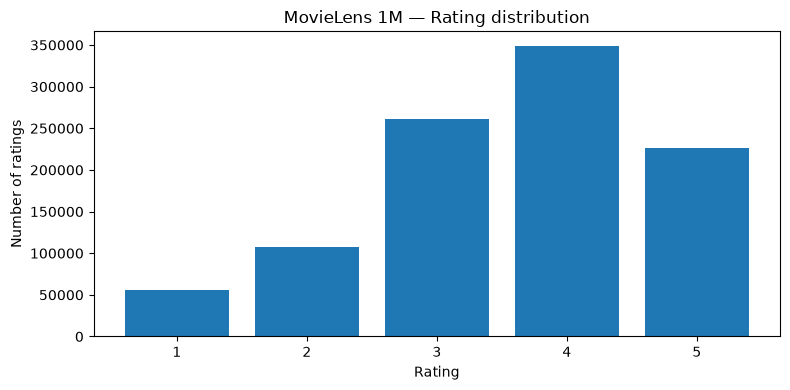

In [3]:
rating_counts = ratings["rating"].value_counts().sort_index()
plt.figure(figsize=(8, 4))
plt.bar(rating_counts.index.astype(str), rating_counts.values)
plt.title("MovieLens 1M — Rating distribution")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.tight_layout()
plt.show()

## 4. Most-rated movies and user activity

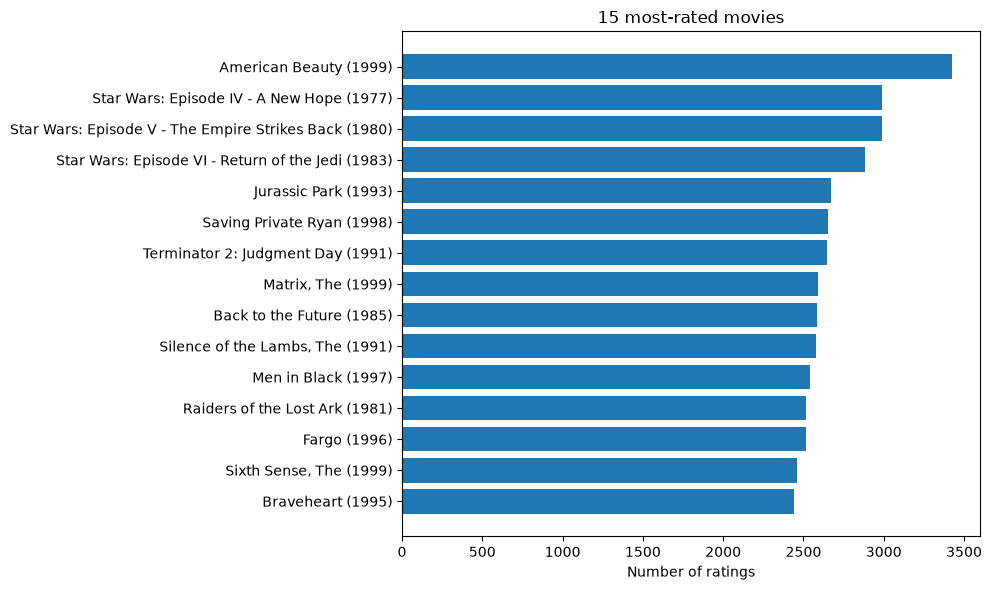

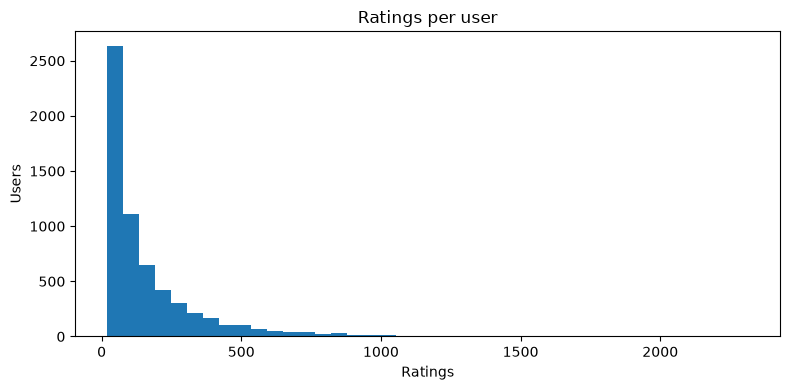

In [4]:
movie_activity = ratings.groupby("movie_id").agg(
    rating_count=("rating", "size"), mean_rating=("rating", "mean")
).merge(movies, on="movie_id")

top = movie_activity.nlargest(15, "rating_count").sort_values("rating_count")
plt.figure(figsize=(10, 6))
plt.barh(top["title"], top["rating_count"])
plt.title("15 most-rated movies")
plt.xlabel("Number of ratings")
plt.tight_layout()
plt.show()

user_activity = ratings.groupby("user_id")["rating"].size()
plt.figure(figsize=(8, 4))
plt.hist(user_activity, bins=40)
plt.title("Ratings per user")
plt.xlabel("Ratings")
plt.ylabel("Users")
plt.tight_layout()
plt.show()

## 5. Genre coverage

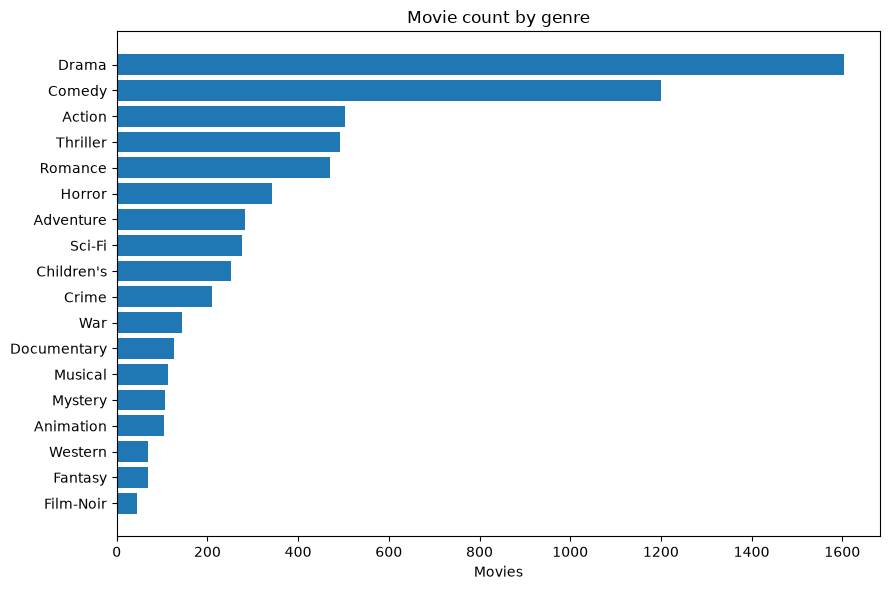

In [5]:
genre_counts = (movies["genres"].str.split("|").explode()
                .value_counts().sort_values())
plt.figure(figsize=(9, 6))
plt.barh(genre_counts.index, genre_counts.values)
plt.title("Movie count by genre")
plt.xlabel("Movies")
plt.tight_layout()
plt.show()

## 6. User-item matrix sparsity

In [6]:
n_users = ratings.user_id.nunique()
n_movies = ratings.movie_id.nunique()
possible = n_users * n_movies
density = len(ratings) / possible
print(f"Observed interactions: {len(ratings):,}")
print(f"Possible user-movie pairs: {possible:,}")
print(f"Matrix density: {density:.4%}")
print(f"Matrix sparsity: {1-density:.4%}")

Observed interactions: 1,000,209
Possible user-movie pairs: 22,384,240
Matrix density: 4.4684%
Matrix sparsity: 95.5316%


## 7. Findings to record

After running the notebook, write a short interpretation here:
- Is the rating distribution skewed?
- Are a small number of films disproportionately popular?
- How sparse is the user-item matrix?
- What does this imply for collaborative filtering and cold-start users/items?

**Important:** Do not infer causality from these descriptive statistics.